In [49]:
!pip3 install numpy matplotlib opencv-python

In [50]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

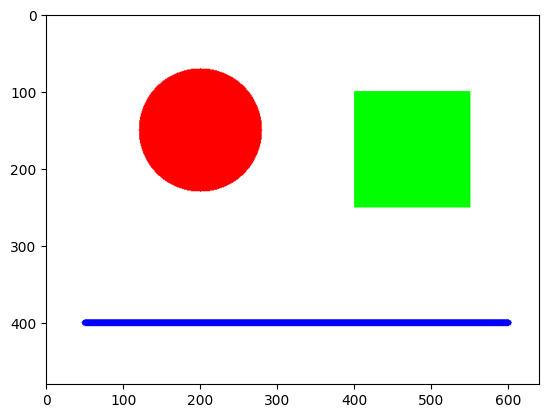

In [59]:
# Image size
w, h = 640, 480

# Create blank white image
img = np.ones((h, w, 3), dtype=np.uint8) * 255

# Draw synthetic shapes
cv2.circle(img, (200, 150), 80, (255, 0, 0), -1)      # blue circle
cv2.rectangle(img, (400, 100), (550, 250), (0, 255, 0), -1) # green rectangle
cv2.line(img, (50, 400), (600, 400), (0, 0, 255), 8)  # red line
plt.imshow(img)

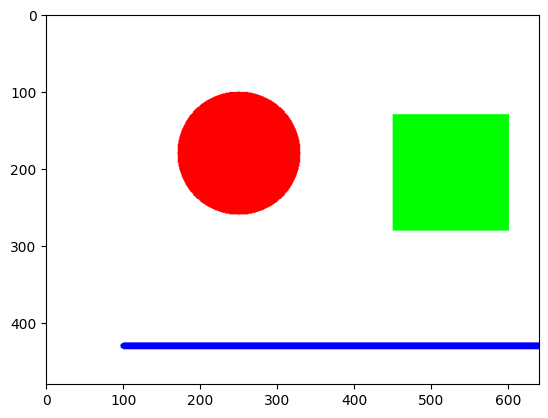

In [60]:
# Create second image
tx, ty = 50, 30
M = np.float32([[1, 0, tx],
                [0, 1, ty]])

# Apply warpAffine
img2 = cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), borderValue=[255,255,255])
plt.imshow(img2)

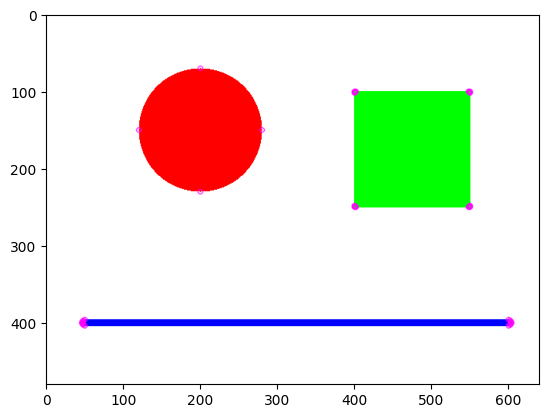

In [69]:
# Initialize FAST detector
fast = cv2.FastFeatureDetector_create(threshold=32, nonmaxSuppression=False)

# Detect keypoints
img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
keypoints = fast.detect(img_gray, None)

# Draw keypoints
img_keypoints = cv2.drawKeypoints(img, keypoints, None, color=(255, 0, 255))
plt.imshow(img_keypoints)

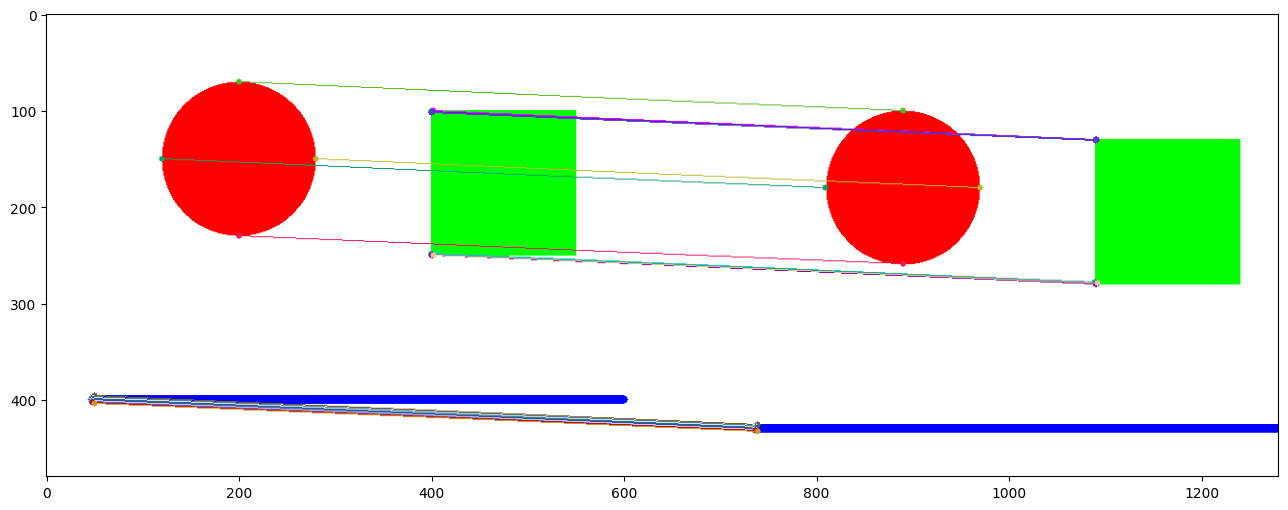

In [67]:
# Convert keypoints to numpy array of points
p0 = np.array([k.pt for k in keypoints], dtype=np.float32).reshape(-1, 1, 2)

# --- Step 2: Track with Lucas–Kanade Optical Flow ---
lk_params = dict(
    winSize=(8, 8),
    maxLevel=5,
    criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01)
)

img_gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)
p1, st, err = cv2.calcOpticalFlowPyrLK(img_gray, img_gray2, p0, None, **lk_params)

# --- Step 3: Keep only successfully tracked points ---
good_new = p1[st == 1]
good_old = p0[st == 1]

h = max(img.shape[0], img2.shape[0])
w = img.shape[1] + img2.shape[1]
canvas = np.zeros((h, w, 3), dtype=np.uint8)

# Place the two images side by side
canvas[:img.shape[0], :img.shape[1]] = img
canvas[:img2.shape[0], img.shape[1]:] = img2

# --- Step 5: Draw correspondences ---
for (x1, y1), (x2, y2) in zip(good_old, good_new):
    pt1 = (int(x1), int(y1))
    pt2 = (int(x2) + img.shape[1], int(y2))  # shift x by width of first image

    color = tuple(np.random.randint(0, 255, 3).tolist())
    cv2.circle(canvas, pt1, 3, color, -1)
    cv2.circle(canvas, pt2, 3, color, -1)
    cv2.line(canvas, pt1, pt2, color, 1)
plt.figure(figsize=(16,6))
plt.imshow(canvas)
